<h2><center>American Sign Language Detection</center></h2>

***I've added the final model as a dataset link. Since running this notebook requires GPU consumtion and it's quite time consuming, if you just want the model, you may get it from here https://www.kaggle.com/namanmanchanda/american-sign-language-model-99-accuracy.***

Table of contents <a id=19></a>
1. [Importing packages](#1)
2. [Data Loading & Augmentation](#2)
    - 2.1 [Checking the shape of data](#3)
    - 2.2 [Checking the shape of one image](#4)
    - 2.3 [Viewing the image](#5)
3. [Modeling](#11)
    - 3.1 [Importing packages](#12)
    - 3.2 [Building the model](#13)
    - 3.3 [Compiling](#14)
    - 3.4 [Model fitting & Early Stopping](#15)
    - 3.5 [Model metrics](#16)
    - 3.6 [Predictions](#17)
    - 3.7 [Saving the model](#18)

### 1. Importing packages <a id=1></a>

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("grassknoted/asl-alphabet")

print("Path to dataset files:", path)

100%|██████████| 1.03G/1.03G [00:59<00:00, 18.5MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/grassknoted/asl-alphabet/versions/1


In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

import cv2
import skimage
from skimage.transform import resize

import tensorflow as tf
from tensorflow import keras
import os

print("Packages imported...")

Packages imported...


### 2. Data Loading & Augmentation <a id=2></a>

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import os

IMG_SIZE = 224
BATCH_SIZE = 32
train_dir = os.path.join(path, 'asl_alphabet_train', 'asl_alphabet_train')

print(f"Veri okunacak dizin: {train_dir}")

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    validation_split=0.3
)

print("Eğitim (Train) seti hazırlanıyor...")
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training'
)

print("Doğrulama (Validation) seti hazırlanıyor...")
val_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation'
)

Veri okunacak dizin: /root/.cache/kagglehub/datasets/grassknoted/asl-alphabet/versions/1/asl_alphabet_train/asl_alphabet_train
Eğitim (Train) seti hazırlanıyor...
Found 60900 images belonging to 29 classes.
Doğrulama (Validation) seti hazırlanıyor...
Found 26100 images belonging to 29 classes.


In [ ]:
import os
print("İndirilen veri seti dizini:", path)
print("Ana dizin içeriği:", os.listdir(path))

if 'asl_alphabet_train' in os.listdir(path):
    train_sub = os.path.join(path, 'asl_alphabet_train')
    print("asl_alphabet_train içeriği:", os.listdir(train_sub))


İndirilen veri seti dizini: /root/.cache/kagglehub/datasets/grassknoted/asl-alphabet/versions/1
Ana dizin içeriği: ['asl_alphabet_train', 'asl_alphabet_test']
asl_alphabet_train içeriği: ['asl_alphabet_train']


#### 2.1 Checking the shape of data <a id=3></a>

In [ ]:
x_batch, y_batch = next(train_generator)
print("X_batch boyutu : ", x_batch.shape)
print("y_batch boyutu : ", y_batch.shape)

X_batch boyutu :  (32, 224, 224, 3)
y_batch boyutu :  (32, 29)


#### 2.2 Checking the shape of one image <a id=4></a>

In [ ]:
print("Tek bir resmin boyutu : ", x_batch[0].shape)


Tek bir resmin boyutu :  (224, 224, 3)


#### 2.3 Viewing the image <a id=5></a>

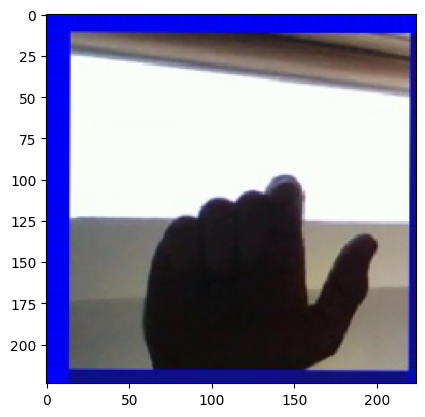

In [ ]:
plt.imshow(x_batch[0])
plt.show()


### 3. Modeling <a id=11></a>

#### 3.1 Importing packages <a id=12></a>

In [ ]:
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Activation, Dense, Flatten
print("Packages imported...")

Packages imported...


#### 3.2 Building the model <a id=13></a>

In [ ]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout

base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
base_model.trainable = True

model = Sequential()
model.add(base_model)
model.add(GlobalAveragePooling2D())
model.add(Dense(256, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(29, activation='softmax'))

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 29)             │         7,453 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,119,709 (92.01 MB)

 Trainable params: 24,066,589 (91.81 MB)

 Non-trainable params: 53,120 (207.50 KB)

#### 3.3 Compiling <a id=14></a>

In [ ]:
from tensorflow.keras.optimizers import Adam

optimizer = Adam(learning_rate=0.0001)

model.compile(optimizer=optimizer,
              loss='categorical_crossentropy',
              metrics=['accuracy'])

#### 3.4 Model fitting & Early Stopping <a id=15></a>

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, Callback
import time

class HourlyReportAgent(Callback):
    def __init__(self, report_path='proje_egitim_raporu.txt'):
        super(HourlyReportAgent, self).__init__()
        self.report_path = report_path
        self.start_time = None
        self.next_report_hour = 1

    def on_train_begin(self, logs=None):
        self.start_time = time.time()
        with open(self.report_path, 'w', encoding='utf-8') as f:
            f.write("=== 📊 PROJE ÖDEVİ: SAATLİK EĞİTİM RAPORU 📊 ===\n")
            f.write(f"⏱️ Eğitim Başlangıç Zamanı: {time.ctime(self.start_time)}\n\n")
        print("🤖 Saatlik Raporlama Ajanı aktif edildi! Raporlar kaydedilecek...")

    def on_epoch_end(self, epoch, logs=None):
        current_time = time.time()
        elapsed_seconds = current_time - self.start_time
        elapsed_hours = elapsed_seconds / 3600.0

        # Eğer geçen süre 1 saati (veya katlarını) aştıysa rapor oluştur
        if elapsed_hours >= self.next_report_hour:
            logs = logs or {}
            report_text = (
                f"--- ⏳ {self.next_report_hour}. Saat Raporu ⏳ ---\n"
                f"🔄 Tamamlanan Epoch: {epoch + 1}\n"
                f"⏱️ Geçen Süre: {elapsed_hours:.2f} saat\n"
                f"📈 Accuracy (Eğitim Başarısı): {logs.get('accuracy', 0):.4f}\n"
                f"📉 Loss (Eğitim Kaybı): {logs.get('loss', 0):.4f}\n"
                f"🎯 Val Accuracy (Doğrulama Başarısı): {logs.get('val_accuracy', 0):.4f}\n"
                f"⚠️ Val Loss (Doğrulama Kaybı): {logs.get('val_loss', 0):.4f}\n"
                f"---------------------------\n\n"
            )
            with open(self.report_path, 'a', encoding='utf-8') as f:
                f.write(report_text)
            print(f"\n🤖 [Ajan]: {self.next_report_hour}. saat raporu '{self.report_path}' dosyasına kaydedildi! 📝")
            self.next_report_hour += 1

    def on_train_end(self, logs=None):
        current_time = time.time()
        total_elapsed_hours = (current_time - self.start_time) / 3600.0
        with open(self.report_path, 'a', encoding='utf-8') as f:
            f.write("\n=== ✅ EĞİTİM TAMAMLANDI ✅ ===\n")
            f.write(f"🏁 Bitiş Zamanı: {time.ctime(current_time)}\n")
            f.write(f"⌛ Toplam Geçen Süre: {total_elapsed_hours:.2f} saat\n")
        print("🤖 [Ajan]: Eğitim bitti. Son durum rapora işlendi. 🎉")

# Callbacks tanımlamaları
# patience 5'ten 10'a çıkarıldı ki eğitim daha uzun sürsün
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
hourly_agent = HourlyReportAgent('proje_egitim_raporu.txt')

# Eğitimi başlatıyoruz (Maksimum epoch 75 yapıldı)
history = model.fit(
    train_generator,
    epochs=75,
    validation_data=val_generator,
    callbacks=[early_stop, hourly_agent],
    verbose=1
)

🤖 Saatlik Raporlama Ajanı aktif edildi! Raporlar kaydedilecek...
Epoch 1/75
1904/1904 ━━━━━━━━━━━━━━━━━━━━ 1397s 699ms/step - accuracy: 0.9641 - loss: 0.1405 - val_accuracy: 0.9103 - val_loss: 0.3588
Epoch 2/75
1904/1904 ━━━━━━━━━━━━━━━━━━━━ 1289s 677ms/step - accuracy: 0.9934 - loss: 0.0273 - val_accuracy: 0.9598 - val_loss: 0.1586
Epoch 3/75
1904/1904 ━━━━━━━━━━━━━━━━━━━━ 0s 508ms/step - accuracy: 0.9954 - loss: 0.0224
🤖 [Ajan]: 1. saat raporu 'proje_egitim_raporu.txt' dosyasına kaydedildi! 📝
1904/1904 ━━━━━━━━━━━━━━━━━━━━ 1292s 679ms/step - accuracy: 0.9953 - loss: 0.0218 - val_accuracy: 0.9441 - val_loss: 0.2762
Epoch 4/75
1904/1904 ━━━━━━━━━━━━━━━━━━━━ 1295s 680ms/step - accuracy: 0.9955 - loss: 0.0202 - val_accuracy: 0.9688 - val_loss: 0.1460
Epoch 5/75
1904/1904 ━━━━━━━━━━━━━━━━━━━━ 1311s 688ms/step - accuracy: 0.9964 - loss: 0.0152 - val_accuracy: 0.8384 - val_loss: 0.6735
Epoch 6/75
1904/1904 ━━━━━━━━━━━━━━━━━━━━ 0s 517ms/step - accuracy: 0.9959 - loss: 0.0170
🤖 [Ajan]: 2. saa

#### 3.5 Model metrics <a id=16></a>

##### 3.5.1 Metrics from model history

In [ ]:
metrics = pd.DataFrame(model.history.history)
print("The model metrics are")
metrics

The model metrics are


,accuracy,loss,val_accuracy,val_loss
0,0.964138,0.140460,0.910345,0.358778
1,0.993415,0.027272,0.959808,0.158571
2,0.995337,0.021794,0.944061,0.276235
3,0.995517,0.020238,0.968774,0.145994
4,0.996420,0.015235,0.838429,0.673488
5,0.997258,0.011563,0.964483,0.162120
6,0.996847,0.013671,0.953525,0.190149
7,0.997094,0.011596,0.965977,0.164420
8,0.998374,0.007176,0.967586,0.142408
9,0.997882,0.009434,0.973908,0.120235


##### 3.5.2 Plotting the training and validation loss

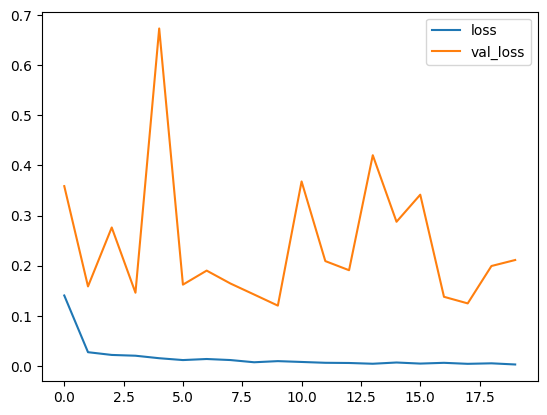

In [ ]:
metrics[['loss','val_loss']].plot()
plt.show()

##### 3.5.3 Plotting the training and validation accuracy

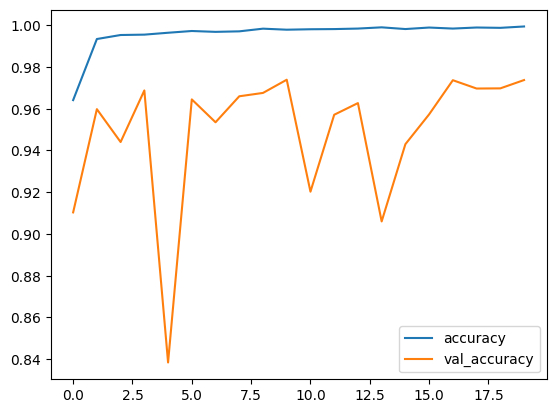

In [ ]:
metrics[['accuracy','val_accuracy']].plot()
plt.show()

##### 3.5.4 Model evaluation

In [ ]:
model.evaluate(val_generator, verbose=1)


816/816 ━━━━━━━━━━━━━━━━━━━━ 329s 403ms/step - accuracy: 0.9741 - loss: 0.1184


[0.11838877201080322, 0.9740996360778809]

#### 3.6 Predictions <a id=17></a>

In [ ]:
import numpy as np

test_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

predictions = np.argmax(model.predict(test_generator), axis=-1)
y_test = test_generator.classes
print("Predictions done...")

Found 26100 images belonging to 29 classes.
816/816 ━━━━━━━━━━━━━━━━━━━━ 335s 405ms/step
Predictions done...


##### 3.6.1 Classification report

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       0.98      1.00      0.99       900
           1       1.00      0.99      0.99       900
           2       1.00      0.97      0.99       900
           3       1.00      1.00      1.00       900
           4       0.94      0.99      0.96       900
           5       1.00      1.00      1.00       900
           6       1.00      0.97      0.98       900
           7       0.98      1.00      0.99       900
           8       0.94      0.79      0.86       900
           9       0.85      0.91      0.88       900
          10       1.00      1.00      1.00       900
          11       0.99      1.00      1.00       900
          12       0.97      1.00      0.98       900
          13       1.00      0.96      0.98       900
          14       0.99      0.97      0.98       900
          15       0.97      1.00      0.99       900
          16       1.00      0.98      0.99       900
          17       0.88    

##### 3.6.3 Testing on completely unseen Test Images
Eğitim ve doğrulama setinde **hiç bulunmayan**, tamamen yepyeni test resimleri üzerinde modelin tahminlerini deniyoruz.

Toplam 28 yepyeni test resmi bulundu. Rastgele 5 tanesi seçiliyor...


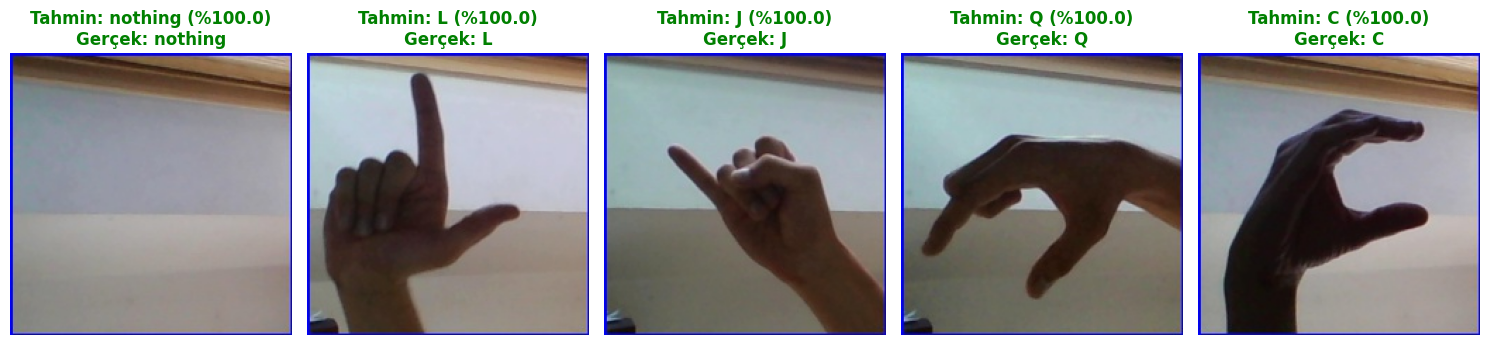

In [ ]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image

test_base = os.path.join(path, 'asl_alphabet_test')
test_dir = test_base
if 'asl_alphabet_test' in os.listdir(test_base):
    test_dir = os.path.join(test_base, 'asl_alphabet_test')

class_labels = {v: k for k, v in train_generator.class_indices.items()}

test_images = [f for f in os.listdir(test_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

if not test_images:
    print("Test dizininde resim bulunamadı:", test_dir)
else:
    print(f"Toplam {len(test_images)} yepyeni test resmi bulundu. Rastgele 5 tanesi seçiliyor...")
    samples = random.sample(test_images, min(5, len(test_images)))

    plt.figure(figsize=(15, 5))
    for i, img_name in enumerate(samples):
        img_path = os.path.join(test_dir, img_name)

        img = image.load_img(img_path, target_size=(IMG_SIZE, IMG_SIZE))
        img_array = image.img_to_array(img)
        img_array = np.expand_dims(img_array, axis=0) / 255.0

        prediction = model.predict(img_array, verbose=0)
        predicted_class_idx = np.argmax(prediction)
        predicted_label = class_labels[predicted_class_idx]
        confidence = np.max(prediction) * 100

        true_label = img_name.split('_')[0]

        plt.subplot(1, len(samples), i+1)
        plt.imshow(image.load_img(img_path))

        color = 'green' if predicted_label == true_label else 'red'
        plt.title(f"Tahmin: {predicted_label} (%{confidence:.1f})\nGerçek: {true_label}", color=color, fontweight='bold')
        plt.axis('off')

    plt.tight_layout()
    plt.show()

#### 3.7 Saving the model <a id=18></a>

In [ ]:
model.save('ASL.h5')
print("Model saved successfully...")

Model saved successfully...


[back to top](#19)